%%markdown
# Inspect an aerial image and building labels

Compare one image chip, a small image cutout, with mapped building pixels. The white mask is a
reference derived from mapped footprints, not a model prediction or a survey.
[Open in Colab](https://colab.research.google.com/github/jfemiani/cse620b-public/blob/main/Lessons/12-Urban-Infrastructure/demo-building-imagery.ipynb) |
[Urban infrastructure lecture](https://github.com/jfemiani/cse620b-public/blob/main/Lessons/12-Urban-Infrastructure/slides/urban-infrastructure.md)

**Source:** Humanitarian OpenStreetMap Team (HOT),
[VHR Building Segmentation Dataset, project 11102, Tajikistan](https://huggingface.co/datasets/hotosm/vhr-building-segmentation).
The image is from OpenAerialMap; building polygons from OpenStreetMap were
converted to pixel labels. This archive is pinned to a dataset revision and downloads
approximately 7.2 MB. The dataset describes zoom level 19, approximately
0.3 m per pixel at the equator; the image's acquisition date and native
sensor resolution were not verified. Do not treat that figure as a local
measurement of resolution.

Imagery: CC BY 4.0, attribution **contributors of Open Imagery Network**.
Labels: ODbL 1.0, attribution **OpenStreetMap contributors**. See the
[dataset licensing and attribution](https://huggingface.co/datasets/hotosm/vhr-building-segmentation#licensing).
Footprints can be incomplete, inaccurate, or from a different date than the
imagery. This is a qualitative inspection, not independent validation.

In [1]:
from io import BytesIO
import tarfile
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

archive_url = "https://huggingface.co/datasets/hotosm/vhr-building-segmentation/resolve/8d3e64e5c69aa37209953cce3a48df1092bc7c94/raw/project_11102/data.tar.gz"
chip_name = "OAM-364179-201947-19.tif"
with urlopen(archive_url, timeout=60) as response:
    archive_bytes = response.read()
with tarfile.open(fileobj=BytesIO(archive_bytes), mode="r:gz") as archive:
    image = np.array(Image.open(BytesIO(archive.extractfile(f"chips/{chip_name}").read())).convert("RGB"))
    mask = np.array(Image.open(BytesIO(archive.extractfile(f"masks/{chip_name}").read()))) > 0

print(f"Image: {image.shape}; building mask: {mask.shape}")
print(f"Mapped building pixels: {mask.mean():.1%}")

Image: (256, 256, 3); building mask: (256, 256)
Mapped building pixels: 10.2%


%%markdown
## Compare image and footprint labels

Look for roofs that line up with the yellow overlay. Where does the mask
disagree with what you see? Trees, shadows, image geometry, and differences
in mapping dates can all complicate the comparison. The first panel shows
the image, the second shows white building pixels on a black background,
and the third overlays mapped pixels on the image in yellow.

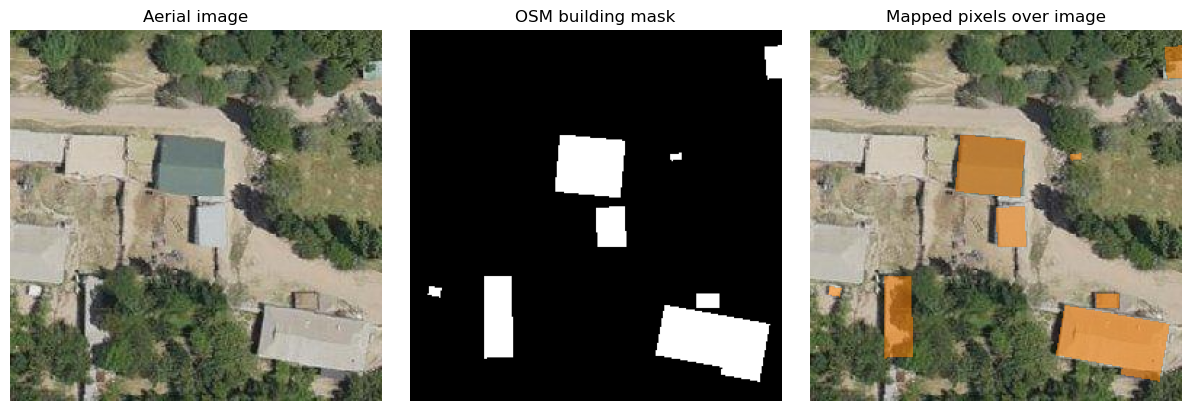

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
axes[0].imshow(image)
axes[0].set_title("Aerial image")
axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("OSM building mask")
axes[2].imshow(image)
axes[2].imshow(np.ma.masked_where(~mask, mask), cmap="Wistia", alpha=0.55, vmin=0, vmax=1)
axes[2].set_title("Mapped pixels over image")
for axis in axes:
    axis.axis("off")
plt.show()

%%markdown
## What can this label support?

The binary mask describes mapped building area, but it does not identify
which pixels belong to each individual building. It cannot alone tell us
whether touching buildings have been merged, or how many buildings are
present. For counting, preserve individual reference footprints and use an
explicit object-matching rule. Connected regions are only a proxy: touching
buildings can become one region. Try the companion metrics notebook to see
how a merge affects pixel and object scores.